# Analise Exploratíria de Dados (EDA)

| Secao | Descricao |
|---|---|
| 1.0 | Configuracao do Ambiente |
| 2.0 | Carregamento da Base Principal (train_base) |
| 3.0 | Auditoria de Granularidade (case_id) |
| 4.0 | Distribuicao da Variavel Alvo e Nulos |
| 5.0 | Analise Temporal e Sazonalidade |
| 6.0 | Conclusao da EDA |

---

## 1.0 Configuracao do Ambiente

**O que faz:** Inicializa o runtime e o caminho raiz do projeto de forma dinamica via `pathlib`, carrega credenciais Kaggle a partir do `.env` e importa as funcoes especializadas dos modulos `src.pipeline`, `src.plots` e `src.drift`.

**Por que importa:** Adota a arquitetura modular orientada a producao (ML Engineering), substituindo modulos monoliticos e garantindo total reprodutibilidade tanto em ambiente local quanto em instancias remotas no Google Colab.

**Como usar:** Execute uma vez por sessao. O ambiente e os caminhos de busca do Python sao configurados dinamicamente.


In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# 1. Resolucao robusta da raiz do projeto (compativel com Colab e Local)
current_dir = Path(os.getcwd()).resolve()

# Identifica se 'src' esta no diretorio atual, no pai, ou dentro da subpasta Projeto_06
if (current_dir / 'src').exists():
    PROJECT_ROOT = current_dir
elif (current_dir / 'Projeto_06' / 'src').exists():
    PROJECT_ROOT = current_dir / 'Projeto_06'
elif (current_dir.parent / 'src').exists():
    PROJECT_ROOT = current_dir.parent
elif Path('/content/Projeto_06/src').exists():
    PROJECT_ROOT = Path('/content/Projeto_06')
else:
    raise FileNotFoundError("Diretorio raiz contendo a pasta 'src' nao foi encontrado.")

# 2. Navega para o diretorio do projeto
os.chdir(PROJECT_ROOT)

# 3. Adiciona a raiz ao sys.path para garantir que o Python enxergue o pacote 'src'
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Diretorio de trabalho configurado: {os.getcwd()}")
print("Caminhos de busca do Python atualizados com sucesso.")

# 4. Importacoes especializadas dos modulos de src/
from src.pipeline import (
    setup_environment,
    download_competition,
    get_table_groups,
    carregar_familia,
    downcast_train_base,
)
from src.plots import (
    analisar_valores_nulos,
    plot_target_distribution,
    plot_sazonalidade,
)
from src.drift import (
    teste_qui_quadrado_temporal,
)

print("Modulos do pacote src/ importados com sucesso!")

# Setup do ambiente e carga dos metadados de tabelas
PROJECT_ROOT = setup_environment(str(PROJECT_ROOT))
base_dir = download_competition()
train_dir = base_dir / 'parquet_files' / 'train'
grupos_tabelas = get_table_groups(train_dir)

Diretorio de trabalho configurado: /content
Caminhos de busca do Python atualizados com sucesso.


Modulos do pacote src/ importados com sucesso!
Ambiente configurado. Token Kaggle carregado.


100%|██████████| 3.14G/3.14G [00:36<00:00, 92.1MB/s]

Extracting files...


Dados localizados em: /root/.cache/kagglehub/competitions/home-credit-credit-risk-model-stability
Foram mapeadas 17 familias de tabelas.


---

## 2.0 Carregamento da Base Principal (train_base)

**O que mede:** a `train_base.parquet` e a espinha dorsal do dataset. Contem `case_id`, `target`, `date_decision`, `MONTH`, `WEEK_NUM`, `num_group1` e `num_group2`.

**Por que importa:** todas as analises e merges futuros se ancoram nesta tabela. O downcast de tipos reduz drasticamente o consumo de RAM.

**Como ler:** `target=1` indica default. `MONTH` e `WEEK_NUM` sao particoes temporais da competicao.

In [2]:
import pandas as pd

df_base = carregar_familia(grupos_tabelas, 'train_base')
df_base = downcast_train_base(df_base)

print(f"Shape: {df_base.shape}")
print(f"Memoria: {df_base.memory_usage().sum() / (1024**2):.2f} MB")
display(df_base.head())

Carregando 'train_base' (1 arquivo(s))...
Shape: (1526659, 5)
Memoria: 27.66 MB


,case_id,date_decision,MONTH,WEEK_NUM,target
0,0,2019-01-03,201901,0,0
1,1,2019-01-03,201901,0,0
2,2,2019-01-04,201901,0,0
3,3,2019-01-03,201901,0,0
4,4,2019-01-04,201901,0,1


In [ ]:
# Dicionario de features
df_descricao = pd.read_csv(base_dir / 'feature_definitions.csv')
display(df_descricao.head())

,Variable,Description
0,actualdpd_943P,Days Past Due (DPD) of previous contract (actu...
1,actualdpdtolerance_344P,DPD of client with tolerance.
2,addres_district_368M,District of the person's address.
3,addres_role_871L,Role of person's address.
4,addres_zip_823M,Zip code of the address.


---

## 3.0 Análise do (case_id)

**O que mede:** quantidade total de registos, unicidade do `case_id` e ausencia de duplicados.

**Por que importa:** cada `case_id` representa um contrato de credito unico. Duplicados invalidariam merges futuros e inflariam metricas.

**Como ler:** a contagem total deve ser igual ao numero de `case_id` unicos.

In [ ]:
total_registos = len(df_base)
unique_cases = df_base['case_id'].nunique()
duplicados = total_registos - unique_cases

print(f'Total de registos:     {total_registos:>10,}')
print(f'case_id unicos:        {unique_cases:>10,}')
print(f'Duplicados:            {duplicados:>10,}')

if duplicados == 0:
    print('\nGranularidade preservada -- 1 linha por case_id.')
else:
    print(f'\nALERTA: {duplicados:,} case_ids duplicados.')
    display(df_base['case_id'].value_counts()[lambda x: x > 1].head(10))

Total de registos:      1,526,659
case_id unicos:         1,526,659
Duplicados:                     0

Granularidade preservada -- 1 linha por case_id.


---

## 4.0 Distribuicao da Variavel Alvo e Nulos

**O que mede:** proporcao de contratos em default (`target=1`) versus adimplentes (`target=0`), e presenca de valores nulos na `train_base`.

**Por que importa:** o desbalanceamento define a estrategia de modelacao (metricas, threshold, amostragem). Nulos na base podem indicar clientes sem historico no bureau.

**Como ler:** barras cinza (adimplentes) versus vermelho (default). O ratio indica quantos adimplentes existem por cada caso de default.

Distribuicao do target:

  target=0 (adimplente):  1,478,665  (96.86%)
  target=1 (default):        47,994  (3.14%)

  Ratio (0:1):           30.8:1


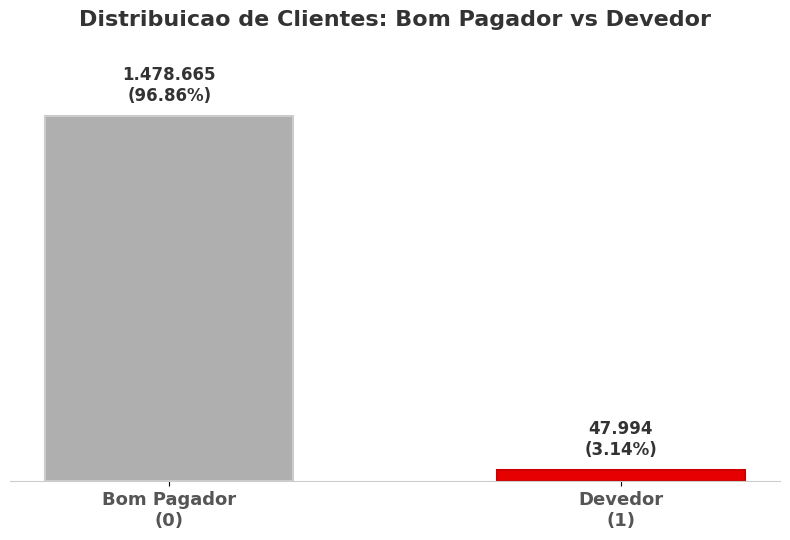

In [5]:
target_counts, target_pct, ratio = plot_target_distribution(df_base)

### 4.1 Valores Nulos na train_base

Verifica se existem dados faltantes nas colunas da base principal.

In [6]:
df_nulos = analisar_valores_nulos(df_base, plotar=True, figsize=(10, 4))

Nenhum valor nulo encontrado no DataFrame.


---

## 5.0 Analise Temporal e Sazonalidade

**O que mede:** periodo coberto pelos dados, volume mensal de contratos e evolucao da taxa de default ao longo do tempo.

**Por que importa:** a competicao avalia **estabilidade temporal** do modelo. Periodos com taxa de default anomala ou volume reduzido podem indicar mudanca de regime economico.

**Como ler:** barras cinza (volume, eixo esquerdo) versus linha vermelha (taxa de default, eixo direito). Rotulos nos pontos mostram o valor exato.

Periodo: 2019-01-01 -> 2020-10-05
Meses unicos: 22
Volume medio/mes: 69,394


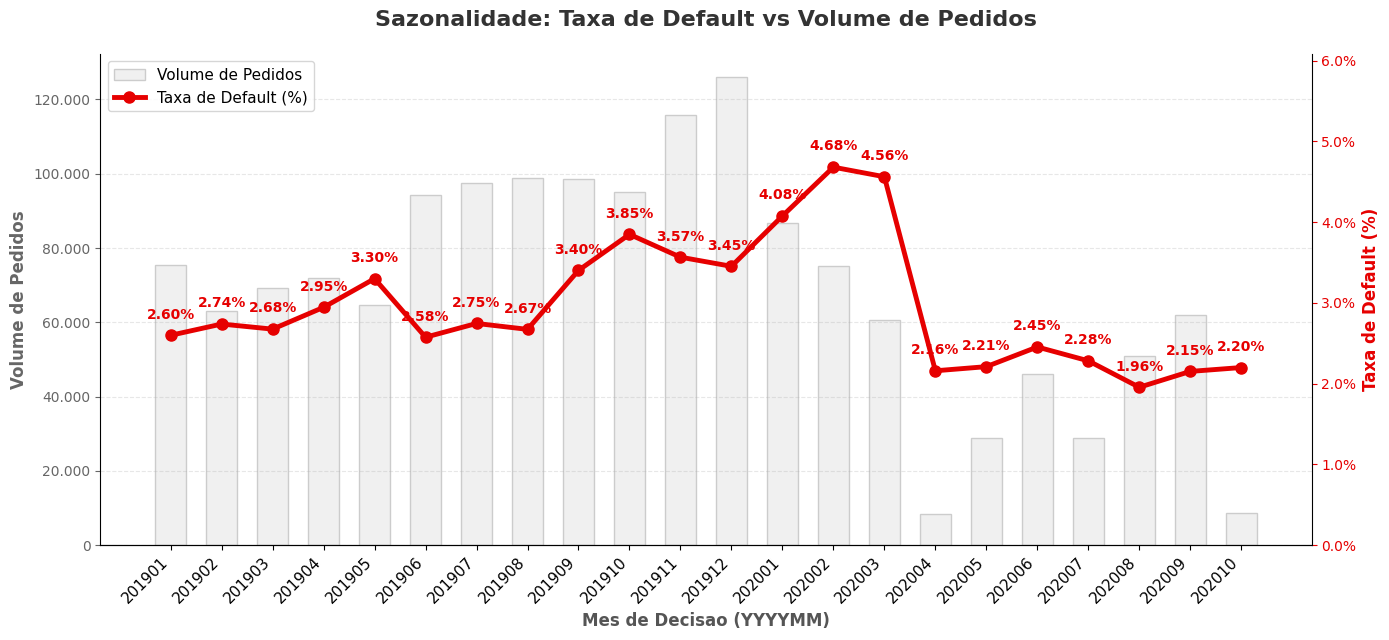

,Default Rate (%),Volume
Mes,,
201901,2.60%,"75,529"
201902,2.74%,"63,064"
201903,2.68%,"69,147"
201904,2.95%,"72,012"
201905,3.30%,"64,594"
201906,2.58%,"94,398"
201907,2.75%,"97,566"
201908,2.67%,"98,741"
201909,3.40%,"98,706"


In [7]:
taxa_mensal_display = plot_sazonalidade(df_base)
display(taxa_mensal_display.style.format({'Default Rate (%)': '{:.2f}%', 'Volume': '{:,.0f}'}))

### 5.1 Teste Qui-Quadrado de Independencia (Target Drift)

**O que mede:** se a taxa de default e estatisticamente independente do mes de decisao.

**Por que importa:** um p-valor baixo confirma que existem diferencas significativas entre meses (target drift). O V de Cramer quantifica a magnitude dessa dependencia.

**Como ler:** p-valor < 0.05 rejeita H0 (independencia). V de Cramer baixo (< 0.10) indica que, apesar de estatisticamente significativa, a variacao entre meses tem magnitude pequena.

In [ ]:
resultados_chi2 = teste_qui_quadrado_temporal(taxa_mensal_display)

Qui-Quadrado:            2626.24
Graus de Liberdade (gl): 21
P-valor:                 0.0000e+00
Frequencia esperada min: 260.58
V de Cramer:             0.0415


> **P-valor ~ 0.0000** (H0 rejeitada): as diferencas de default rate entre meses sao estatisticamente significativas. Existe target drift.
>
> **V de Cramer = 0.0415** (baixo): apesar da significancia estatistica, a magnitude da variacao e pequena. As variaveis mes e target possuem correlacao fraca -- o drift existe, mas nao e estruturalmente dominante.

---

## 6.0 Conclusao da EDA

> ### Diagnostico Consolidado -- `train_base.parquet`
>
> **1. Identificacao (`case_id`)**
> * 1.526.659 contratos unicos. Granularidade OK.
>
> **2. Variavel Alvo (`target`)**
> * Default rate global: 3,14%
> * Ratio adimplente vs default: 30,8:1
> * Desbalanceamento significativo: estrategias como `class_weight` ou subamostragem serao necessarias.
>
> **3. Qualidade dos Dados**
> * Nenhum valor nulo detetado na base principal.
>
> **4. Análise Temporal e Contexto Macroeconômico**
> * **Período:** 2019-01 a 2020-10 (22 meses)
> * **Mês com maior default:** 2020-02 (4,68%)
> 
> 
> * **Mês com menor default:** 2020-08 (1,96%)
> 
> 
> * **Amplitude:** 2,73 p.p.
> * **Sazonalidade de Consumo:** Observa-se um pico expressivo no volume de pedidos de crédito no final do ano (novembro e dezembro de 2019), refletindo o aquecimento natural do mercado.
> 
> 
> * **Choque da Pandemia (COVID-19):** Forte impacto macroeconômico visível nos dados. A taxa de inadimplência atinge seu nível máximo histórico no primeiro trimestre de 2020 (4,68% em fevereiro), e é imediatamente seguida por um colapso brutal no volume de concessões de crédito a partir de abril de 2020 (queda para cerca de 8.200 pedidos).
> 
> 
> * **Target Drift:** Estatisticamente significativo (p ~ 0), mas com magnitude fraca (V de Cramér = 0.04)
>
> **5. Proximos Passos**
> * Merge Depth 0 com `train_static_0` e `train_static_cb_0` (ver `02_Feature_Engineering.ipynb`).
> * Agregacoes Depth 1/2 de historico de credito.